In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load the Iris dataset
iris = load_iris(as_frame=True)

X = iris.data
y = iris.target

print("Dataset shape:", X.shape)
print("\nFeature names:", list(X.columns))
print("\nTarget classes:", list(iris.target_names))
print("\nClass distribution:")
print(y.value_counts().sort_index())


Dataset shape: (150, 4)

Feature names: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Target classes: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]

Class distribution:
target
0    50
1    50
2    50
Name: count, dtype: int64


In [2]:

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training features shape:", X_train.shape)
print("Testing features shape:", X_test.shape)

print("\nTraining target shape:", y_train.shape)
print("Testing target shape:", y_test.shape)

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index())

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index())


Training features shape: (120, 4)
Testing features shape: (30, 4)

Training target shape: (120,)
Testing target shape: (30,)

Training class distribution:
target
0    40
1    40
2    40
Name: count, dtype: int64

Testing class distribution:
target
0    10
1    10
2    10
Name: count, dtype: int64


In [3]:

# Create the scaler
scaler = StandardScaler()

# Fit on training data and transform it
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the same scaler
X_test_scaled = scaler.transform(X_test)

print("Scaled training data shape:", X_train_scaled.shape)
print("Scaled testing data shape:", X_test_scaled.shape)

print("\nTraining feature means (approximately 0):")
print(np.round(X_train_scaled.mean(axis=0), 4))

print("\nTraining feature standard deviations (approximately 1):")
print(np.round(X_train_scaled.std(axis=0), 4))


Scaled training data shape: (120, 4)
Scaled testing data shape: (30, 4)

Training feature means (approximately 0):
[-0. -0.  0.  0.]

Training feature standard deviations (approximately 1):
[1. 1. 1. 1.]


In [4]:

# Create the SVM classifier
svm_model = SVC(kernel="linear", C=1.0)

# Train the model
svm_model.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred = svm_model.predict(X_test_scaled)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)

print("SVM Model: Linear Kernel")
print("Test Accuracy:", round(accuracy, 4))
print("Test Accuracy (%):", round(accuracy * 100, 2), "%")

print("\nFirst 10 predictions:", y_pred[:10])
print("First 10 actual labels:", y_test.to_numpy()[:10])


SVM Model: Linear Kernel
Test Accuracy: 1.0
Test Accuracy (%): 100.0 %

First 10 predictions: [0 2 1 1 0 1 0 0 2 1]
First 10 actual labels: [0 2 1 1 0 1 0 0 2 1]


Classification Report:

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      1.00      1.00        10
   virginica       1.00      1.00      1.00        10

    accuracy                           1.00        30
   macro avg       1.00      1.00      1.00        30
weighted avg       1.00      1.00      1.00        30

Confusion Matrix:

[[10  0  0]
 [ 0 10  0]
 [ 0  0 10]]


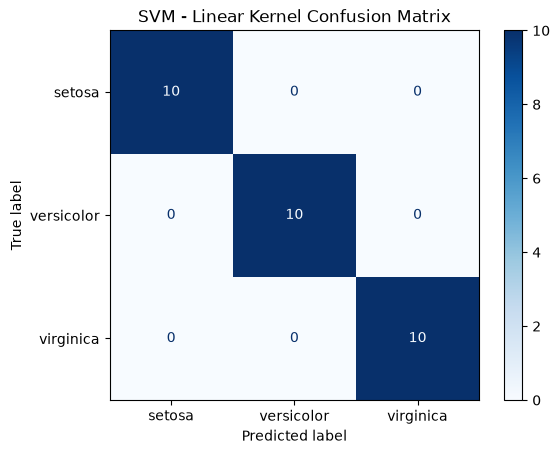

In [5]:

# Generate the classification report
print("Classification Report:\n")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=iris.target_names
    )
)

# Generate the confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:\n")
print(cm)

# Visualize the confusion matrix
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=iris.target_names
)

display.plot(cmap="Blues")
plt.title("SVM - Linear Kernel Confusion Matrix")
plt.show()


In [6]:

# Create an SVM classifier using the RBF kernel
svm_rbf = SVC(kernel="rbf", C=1.0, gamma="scale")

# Train the model
svm_rbf.fit(X_train_scaled, y_train)

# Make predictions
y_pred_rbf = svm_rbf.predict(X_test_scaled)

# Evaluate the model
rbf_accuracy = accuracy_score(y_test, y_pred_rbf)

print("SVM Model: RBF Kernel")
print("Test Accuracy:", round(rbf_accuracy, 4))
print("Test Accuracy (%):", round(rbf_accuracy * 100, 2), "%")

print("\nClassification Report:\n")
print(
    classification_report(
        y_test,
        y_pred_rbf,
        target_names=iris.target_names
    )
)


SVM Model: RBF Kernel
Test Accuracy: 0.9667
Test Accuracy (%): 96.67 %

Classification Report:

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



In [7]:

from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Define the parameter grid
param_grid = [
    {
        "kernel": ["linear"],
        "C": [0.1, 1, 10, 100]
    },
    {
        "kernel": ["rbf"],
        "C": [0.1, 1, 10, 100],
        "gamma": ["scale", 0.01, 0.1, 1]
    }
]

# Use stratified 5-fold cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Set up GridSearchCV
grid_search = GridSearchCV(
    estimator=SVC(),
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1,
    return_train_score=True
)

# Train and compare configurations
grid_search.fit(X_train_scaled, y_train)

print("Best parameters:", grid_search.best_params_)
print("Best mean CV accuracy:", round(grid_search.best_score_, 4))
print("Best mean CV accuracy (%):", round(grid_search.best_score_ * 100, 2), "%")


Best parameters: {'C': 0.1, 'kernel': 'linear'}
Best mean CV accuracy: 0.975
Best mean CV accuracy (%): 97.5 %


Tuned SVM Model
Best parameters: {'C': 0.1, 'kernel': 'linear'}
Test accuracy: 0.9333
Test accuracy (%): 93.33 %

Classification Report:

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



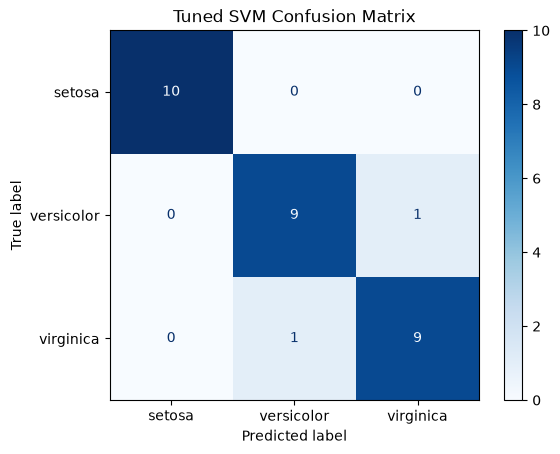

In [8]:

# Retrieve the best SVM model
best_svm_model = grid_search.best_estimator_

# Predict on the test set
y_pred_tuned = best_svm_model.predict(X_test_scaled)

# Calculate test accuracy
tuned_accuracy = accuracy_score(y_test, y_pred_tuned)

print("Tuned SVM Model")
print("Best parameters:", grid_search.best_params_)
print("Test accuracy:", round(tuned_accuracy, 4))
print("Test accuracy (%):", round(tuned_accuracy * 100, 2), "%")

print("\nClassification Report:\n")
print(
    classification_report(
        y_test,
        y_pred_tuned,
        target_names=iris.target_names
    )
)

# Plot the confusion matrix
cm_tuned = confusion_matrix(y_test, y_pred_tuned)

ConfusionMatrixDisplay(
    confusion_matrix=cm_tuned,
    display_labels=iris.target_names
).plot(cmap="Blues")

plt.title("Tuned SVM Confusion Matrix")
plt.show()


                   Model  Test Accuracy  Weighted F1 Score
      Linear SVM (C=1.0)       1.000000           1.000000
         RBF SVM (C=1.0)       0.966667           0.966583
Tuned Linear SVM (C=0.1)       0.933333           0.933333


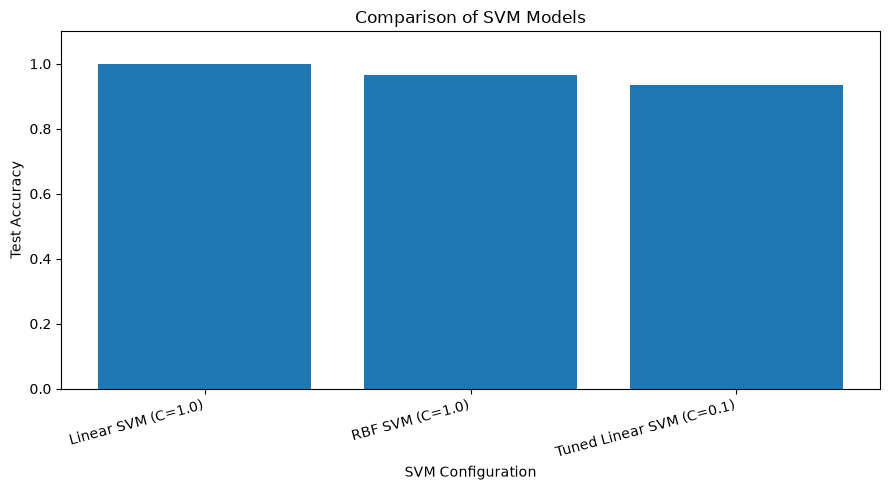

In [9]:

from sklearn.metrics import f1_score

# Compare the three SVM configurations
comparison = pd.DataFrame({
    "Model": [
        "Linear SVM (C=1.0)",
        "RBF SVM (C=1.0)",
        "Tuned Linear SVM (C=0.1)"
    ],
    "Test Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_rbf),
        accuracy_score(y_test, y_pred_tuned)
    ],
    "Weighted F1 Score": [
        f1_score(y_test, y_pred, average="weighted"),
        f1_score(y_test, y_pred_rbf, average="weighted"),
        f1_score(y_test, y_pred_tuned, average="weighted")
    ]
})

print(comparison.to_string(index=False))

# Visualize test accuracy
plt.figure(figsize=(9, 5))
plt.bar(comparison["Model"], comparison["Test Accuracy"])
plt.ylabel("Test Accuracy")
plt.xlabel("SVM Configuration")
plt.title("Comparison of SVM Models")
plt.ylim(0, 1.1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()


In [10]:

import joblib
import json

# Save the best-performing model on this test split
joblib.dump(svm_model, "best_svm_iris.pkl")

# Save the comparison results
comparison.to_csv("svm_model_comparison.csv", index=False)

# Save model evaluation details
results = {
    "dataset": "Iris",
    "best_test_model": "Linear SVM",
    "best_test_model_parameters": svm_model.get_params(deep=False),
    "best_test_accuracy": float(accuracy_score(y_test, y_pred)),
    "rbf_test_accuracy": float(accuracy_score(y_test, y_pred_rbf)),
    "tuned_svm_parameters": grid_search.best_params_,
    "tuned_svm_cv_accuracy": float(grid_search.best_score_),
    "tuned_svm_test_accuracy": float(
        accuracy_score(y_test, y_pred_tuned)
    )
}

with open("svm_evaluation_results.json", "w") as file:
    json.dump(results, file, indent=4, default=str)

print("Files saved successfully:")
print("1. best_svm_iris.pkl")
print("2. svm_model_comparison.csv")
print("3. svm_evaluation_results.json")


Files saved successfully:
1. best_svm_iris.pkl
2. svm_model_comparison.csv
3. svm_evaluation_results.json
